# iROAS in geo experiments — a ratio-metric case study

A real-world application of the Battey & Edgar lens (see notebook
`01_treatment_effect_critique_tutorial.ipynb`).

**Setting.** Growth marketing runs in every geo-unit (region). The treatment
policy *negativizes* the budget in treated geos: marketing cost drops
multiplicatively — routinely by 50%, sometimes by **−99%**. The estimand is

$$\mathrm{iROAS} = \frac{\text{incremental revenue}}{\text{incremental cost}}
= \frac{\Delta R}{\Delta C},$$

a **ratio metric**. Practitioners disagree on how to average it across geos:

1. **average of per-geo ratios** — $\frac{1}{n}\sum_i \Delta R_i / \Delta C_i$
   (the eq.-3.1 analog: a unit-level model-free average);
2. **ratio of aggregates** — $\sum_i \Delta R_i / \sum_i \Delta C_i$
   (the standard geo-experiment estimator);
3. **trimmed ratio** — (2) after trimming geos with extreme per-geo ratios;
4. **WLS regression** — $\Delta R_i$ on $\Delta C_i$ through the origin,
   weighted by the known noise structure (the model-based route).

We simulate under the same *fictitious idealisation* as the paper (both
potential outcomes observable per geo), then relax it with an actual
randomized design at the end.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from logic.simulation_engine import run_study, run_scenarios
from logic.iroas_models import (
    GEO_POPULATIONS,
    GeoiROASModel,
    randomize_assignment,
    randomized_iroas,
)
from logic.likelihoods import fit_size_interaction
from logic.treatment_effect_plots import (
    plot_estimate_stability,
    plot_population_sensitivity,
    plot_geo_ratio_diagnostics,
)

SEED = 20261010
N_GEOS = 200
N_REPS = 300
RHO = 3.0  # true iROAS: each incremental $1 of spend returns $3 of revenue

## 1. The data-generating process

Per geo $i$ with size $\gamma_i$ (heavy-tailed, Zipf-like — a few huge
regions, many tiny ones):

- baseline cost $C_i(0) \propto \gamma_i$ (spend scales with size);
- treated cost $C_i(1) = \kappa \, C_i(0)$ with $\kappa \in (0,1]$ —
  $\kappa = 0.01$ is a −99% negativization. Note this intervention is
  **multiplicative on cost**: a scale-family action, i.e. example 2's
  structure, with stable effect $\log\kappa$ on the log-cost scale;
- revenue $R_i(t) = \text{organic}_i + \rho_i\,C_i(t) + \varepsilon$, with
  noise scale $\sigma_{\text{floor}} + \sigma_r \gamma_i$. The **floor**
  is measurement noise that does *not* shrink with geo size — the realistic
  ingredient that makes tiny geos dangerous for per-geo ratios.

First look: per-geo ratios $\Delta R_i / \Delta C_i$ against geo size, for an
extreme (−99%) and a mild (−5%) negativization.

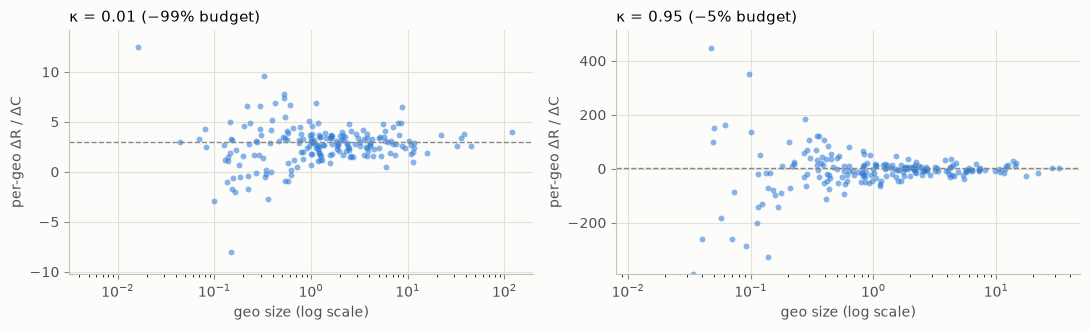

In [2]:
rng = np.random.default_rng(SEED)
deep = GeoiROASModel(GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=0.01)
mild = GeoiROASModel(GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=0.95)

d_deep = deep.draw(n=N_GEOS, n_reps=1, rng=rng)
d_mild = mild.draw(n=N_GEOS, n_reps=1, rng=rng)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), facecolor="#fcfcfb")
for ax, d, label in [(axes[0], d_deep, "κ = 0.01 (−99% budget)"),
                     (axes[1], d_mild, "κ = 0.95 (−5% budget)")]:
    plot_geo_ratio_diagnostics(
        d.gamma[0], (d.revenue1 - d.revenue0)[0], (d.cost1 - d.cost0)[0],
        true_value=RHO, title=label, ax=ax,
    )
fig.tight_layout()
plt.show()

**What to look at:** with a deep budget cut (left) the incremental cost is
large in every geo, so per-geo ratios hug the true iROAS — only the tiniest
geos scatter. With a mild cut (right), $\Delta C_i \approx 0$ everywhere and
per-geo ratios explode across the board.

> **Counter-intuitive but important:** the *extreme* −99% negativization is
> the **well-conditioned** case (big denominators). It is *mild* budget
> changes that make per-geo iROAS ratios blow up.

## 2. World (a): one true iROAS exists (constant ρ)

Every geo has the same $\rho_i \equiv 3$. All four estimators target it —
the question is *how reliably*.

In [3]:
df_a = run_study(deep, n=N_GEOS, n_reps=N_REPS, seed=SEED + 1)
df_a.groupby("estimator")["estimate"].agg(
    ["mean", "std", lambda s: s.quantile(0.05), lambda s: s.quantile(0.95)]
).set_axis(["mean", "std", "q05", "q95"], axis=1).round(3)

,mean,std,q05,q95
estimator,,,,
avg_of_geo_ratios,2.976,0.442,2.259,3.707
ratio_of_aggregates,3.000,0.143,2.766,3.223
trimmed_ratio,3.000,0.144,2.768,3.221
wls_regression,2.996,0.093,2.848,3.152


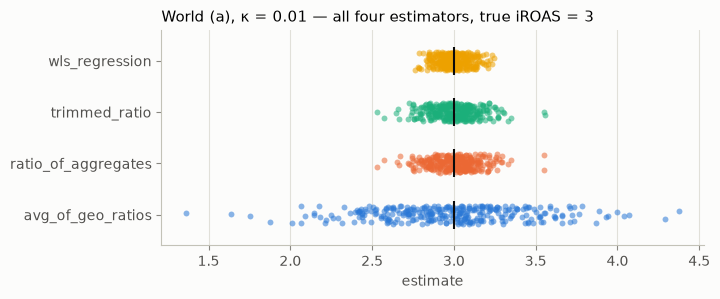

In [4]:
plot_estimate_stability(
    df_a, title="World (a), κ = 0.01 — all four estimators, true iROAS = 3"
)
plt.show()

With −99% negativization everything looks fine (ratios well-conditioned). Now
sweep the negativization depth.

## 3. Sweep: how deep does the budget cut go?

$\kappa \in \{0.01, 0.3, 0.7, 0.95\}$ — from −99% down to a −5% nudge.

In [5]:
sweep = {
    f"κ = {k} (−{round((1 - k) * 100)}%)": GeoiROASModel(
        GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=k)
    for k in (0.01, 0.3, 0.7, 0.95)
}
sc_sweep = run_scenarios(sweep, n=N_GEOS, n_reps=N_REPS, seed=SEED + 2)
sc_sweep.groupby(["scenario", "estimator"])["estimate"].agg(
    ["mean", "std"]).round(2)

mean   std
scenario        estimator                      
κ = 0.01 (−99%) avg_of_geo_ratios    2.99  0.47
                ratio_of_aggregates  3.00  0.15
                trimmed_ratio        3.00  0.15
                wls_regression       3.00  0.09
κ = 0.3 (−70%)  avg_of_geo_ratios    2.94  0.82
                ratio_of_aggregates  3.00  0.18
                trimmed_ratio        3.00  0.18
                wls_regression       3.00  0.11
κ = 0.7 (−30%)  avg_of_geo_ratios    2.84  1.48
                ratio_of_aggregates  3.05  0.45
                trimmed_ratio        3.05  0.45
                wls_regression       3.01  0.27
κ = 0.95 (−5%)  avg_of_geo_ratios    4.01  9.69
                ratio_of_aggregates  3.15  2.64
                trimmed_ratio        3.15  2.66
                wls_regression       3.08  1.59

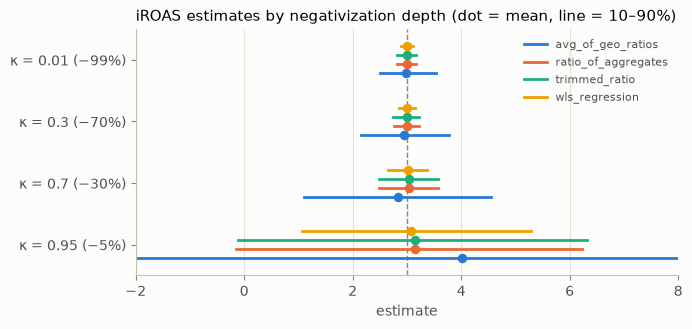

In [6]:
plot_population_sensitivity(
    sc_sweep, true_value=RHO, quantiles=(0.1, 0.9),
    title="iROAS estimates by negativization depth (dot = mean, line = 10–90%)",
)
plt.xlim(-2, 8)
plt.show()

**Takeaways.**

- `avg_of_geo_ratios` degrades first and worst as cuts get milder — by
  κ = 0.95 its replication spread is an order of magnitude wider than WLS.
  This is **example 4's "γ near zero" pathology** wearing ratio-metric
  clothes: unit-level model-free averages are at the mercy of
  badly-conditioned units.
- `wls_regression` — the model-based estimator, which *uses* the known noise
  structure — stays the most stable at every depth.
- Trimming helps the tails but cannot repair a mild intervention: if
  $\Delta C \approx 0$ in every geo, no reweighting of geos fixes the
  denominator.
- **Design implication:** if you must negativize to measure iROAS, negativize
  *hard*. Statistical conditioning and business caution pull in opposite
  directions here, and pretending otherwise biases nothing but your variance.

## 4. World (b): no single iROAS exists (heterogeneous ρᵢ)

Now the marginal ROAS varies with geo size:
$\rho_i = \rho_0 (\gamma_i/\mathrm{med}\,\gamma)^{\delta}$ with
$\delta = 0.3$ — big markets convert ad spend better. Which number is "the"
iROAS?

- `avg_of_geo_ratios` → the **unweighted** mean of $\rho_i$;
- `ratio_of_aggregates` → the **cost-weighted** mean of $\rho_i$
  (dominated by the big geos).

Both are "correct"… for *different estimands* — and both move when the
geo-size population changes. This is **examples 4–5's sample-dependence**,
restated for ratio metrics.

In [7]:
DELTA_SIZE = 0.3
het = {
    pop: GeoiROASModel(dist, rho0=RHO, kappa=0.01,
                       rho_size_exponent=DELTA_SIZE)
    for pop, dist in GEO_POPULATIONS.items()
}
sc_b = run_scenarios(het, n=N_GEOS, n_reps=N_REPS, seed=SEED + 3)

# Each estimator's own large-n target, computed from one huge draw
big = het["zipf_like"].draw(n=200_000, n_reps=1,
                            rng=np.random.default_rng(SEED + 4))
dc = (big.cost1 - big.cost0)[0]
targets = pd.Series({
    "unweighted mean of rho_i": big.rho[0].mean(),
    "cost-weighted mean of rho_i": np.sum(big.rho[0] * dc) / np.sum(dc),
    "rho0 (median geo)": RHO,
}).round(3)
print(targets)
sc_b.groupby(["scenario", "estimator"])["estimate"].mean().unstack(
    "scenario").round(3)

unweighted mean of rho_i       3.317
cost-weighted mean of rho_i    6.343
rho0 (median geo)              3.000
dtype: float64


scenario,homogeneous,zipf_like
estimator,,
avg_of_geo_ratios,3.000,3.331
ratio_of_aggregates,3.038,6.380
trimmed_ratio,3.031,5.169
wls_regression,3.037,4.617


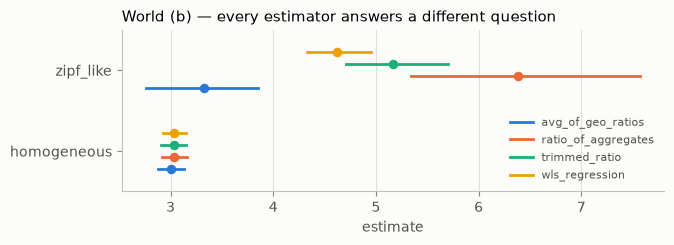

In [8]:
plot_population_sensitivity(
    sc_b, quantiles=(0.1, 0.9),
    title="World (b) — every estimator answers a different question",
)
plt.show()

**What happened:** under the heavy-tailed (`zipf_like`) population the
cost-weighted answer (ratio of aggregates) sits far above the unweighted one;
under near-equal geos (`homogeneous`) they collapse together. Change the
population of geos → change "the iROAS", for every model-free estimator. No
reference line is drawn because **there is no single stable target**.

### The model-based resolution: model the interaction

Battey & Edgar's prescription (§5): systematic effect heterogeneity belongs
*in the model*. Fit $\Delta R_i = \rho_0 (\gamma_i/\mathrm{med})^{\delta}
\Delta C_i + \varepsilon$ and recover the stable pair $(\rho_0, \delta)$ —
a description of *how* iROAS varies with size, valid across geo
populations.

In [9]:
data_b = het["zipf_like"].draw(n=N_GEOS, n_reps=100,
                               rng=np.random.default_rng(SEED + 5))
noise = het["zipf_like"].noise_scale(data_b.gamma)
fit = fit_size_interaction(
    data_b.revenue1 - data_b.revenue0,
    data_b.cost1 - data_b.cost0,
    data_b.gamma,
    weights=1.0 / noise**2,
)
pd.DataFrame({
    "rho0_hat": [fit["rho0"].mean(), fit["rho0"].std()],
    "delta_hat": [fit["delta"].mean(), fit["delta"].std()],
}, index=["mean", "std"]).round(3)

,rho0_hat,delta_hat
mean,3.015,0.298
std,0.113,0.016


The pair (ρ₀ ≈ 3, δ ≈ 0.3) is recovered and — unlike every ratio average
above — means the same thing whatever geos the next experiment samples. Any
aggregate a stakeholder wants (unweighted, cost-weighted, for a specific geo
portfolio) can then be *computed* from the fitted model, with the weighting
chosen deliberately rather than inherited silently from an estimator.

## 5. Reality check: an actual randomized design

Drop the idealisation: randomize geos 50/50, observe only one arm per geo, and
estimate iROAS feasibly as treated-minus-control group means
(ΔR̄ / ΔC̄).

In [10]:
model = GeoiROASModel(GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=0.01)
rng = np.random.default_rng(SEED + 6)
data = model.draw(n=N_GEOS, n_reps=N_REPS, rng=rng)
obs = randomize_assignment(data, p_treated=0.5, rng=rng)
feasible = randomized_iroas(obs["revenue"], obs["cost"], obs["treated"])

ideal = run_study(model, n=N_GEOS, n_reps=N_REPS, seed=SEED + 7)
ideal_roa = ideal[ideal.estimator == "ratio_of_aggregates"]["estimate"]
pd.DataFrame({
    "mean": [np.nanmean(feasible), ideal_roa.mean()],
    "std": [np.nanstd(feasible), ideal_roa.std()],
}, index=["randomized diff-in-means ratio",
          "idealised ratio_of_aggregates"]).round(3)

,mean,std
randomized diff-in-means ratio,2.868,1.898
idealised ratio_of_aggregates,2.993,0.149


The feasible estimator is unbiased but **far noisier**: randomization over
heavy-tailed geos leaves large chance imbalances between arms. (This is why
practical geo-experiment methods add pre-period covariate adjustment, size
stratification, or matching — all of which are model-based repairs, and all
outside this notebook's scope.) The estimand lessons above are unchanged: the
randomized design estimates the *cost-weighted* aggregate, with extra noise on
top.

## 6. Linking back to Battey & Edgar

| Case-study phenomenon | Paper counterpart |
|---|---|
| Budget negativization is multiplicative on cost: stable effect log κ on the log scale | **Example 2** — scale-family actions have a stable transformed effect |
| Tiny geos (or mild cuts) make per-geo ratios explode | **Example 4** — units with γ near zero dominate unit-level model-free averages |
| "Which average is THE iROAS?" has no answer under heterogeneity; every estimator shifts with the geo population | **Examples 4–5** — model-free effects are sample-dependent when stability conditions fail |
| Fit (ρ₀, δ) via an explicit size interaction; compute any aggregate afterwards | **§5** — heterogeneity belongs in the model as interactions, keeping parameters stable |

## 7. Practical guidance

1. **Declare the estimand first.** "Unbiased iROAS" is undefined until you say
   *which* iROAS: unweighted-by-geo, cost-weighted, or a model parameter.
   Under heterogeneity these genuinely differ.
2. **Never average per-geo ratios** when incremental cost can be near zero in
   any geo — mild interventions and tiny geos both do it. If you must, trim —
   and report that the trimming fraction is now part of the estimand.
3. **Ratio of aggregates** is defensible and simple, but understand it is
   cost-weighted: your biggest markets *are* the estimate.
4. **The model-based route** (regression with the right weights, interactions
   for systematic heterogeneity) is the only one whose answer transfers to a
   different portfolio of geos — the paper's central claim, replayed in
   production clothes.
5. **Deep negativizations are statistically kind.** A −99% cut gives large,
   well-conditioned denominators; a −5% nudge gives an experiment that mostly
   measures noise.